# M029, session 25 (2026-09-04) — full session history

Every plotting request made in this session, in the order it was asked, each with the
exact code that produced it and the resulting figure. Use this notebook to trace which
code generated any given picture; `Notebooks/block_plots_M029_s25.ipynb` holds only the
current/final versions.

**Contents**
1. Initial request: full block figures + time-to-reward + Posterior-Anterior(g), trials 19-24
2. Gaussian filtering (sigma = 3 ms)
3. Restrict to the response epoch only
4. Poster figure: Time to Reward, block 2 vs. block 3 (linear scale)
5. Time-to-reward panel: quiescence markers removed (trials 19-24)
6. Poster figure: log scale + merge block 0/1 into "Block 1"
7. Poster figure: single panel, color-coded (rejected)
8. Poster figure: back to 3 panels, no dividing walls
9. Poster figure: color-coded panels, no dividing walls (final)
10. Time-to-reward panel: trial range extended to 18-27 (final)

In [1]:
from pathlib import Path
import sys

repo_root = next((parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (parent / 'ndnf_pipeline').exists()), None)
if repo_root is None:
    raise RuntimeError('Could not locate the repository root')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import datajoint as dj
dj.config.load(str(repo_root / 'dj_local_conf.json'))
dj.conn()

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from ndnf_pipeline import experiment
from ndnf_pipeline.plot import behavior_plots as bp
from ndnf_pipeline.plot.behavior_plots import plot_block_force_figure

subject_id = 'M029'
session = 25
trials_by_block = {2: [19, 20], 3: [21, 22, 23, 24]}
block_colors = {2: 'tab:blue', 3: 'tab:red'}

C:\NDNF-pipeline\.venv\Lib\site-packages\datajoint\plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82


[2026-09-18 12:35:37,268][INFO]: DataJoint is configured from C:\NDNF-pipeline\dj_local_conf.json


[2026-09-18 12:35:37,357][INFO]: DataJoint 0.14.9 connected to rozmar@datajoint.ndnf.koki.hun-ren.hu:3306


## 1. Initial request

> "make a plot from animal 29, day 25 (2026/09/04), trials 19 to 24 [...] the time to
> get the reward x block plot as well the posterior anterior (g) plots"

Trials 19-24 span block 2 (trials 14-20) and block 3 (trials 21-27). No smoothing or
epoch restriction yet.

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


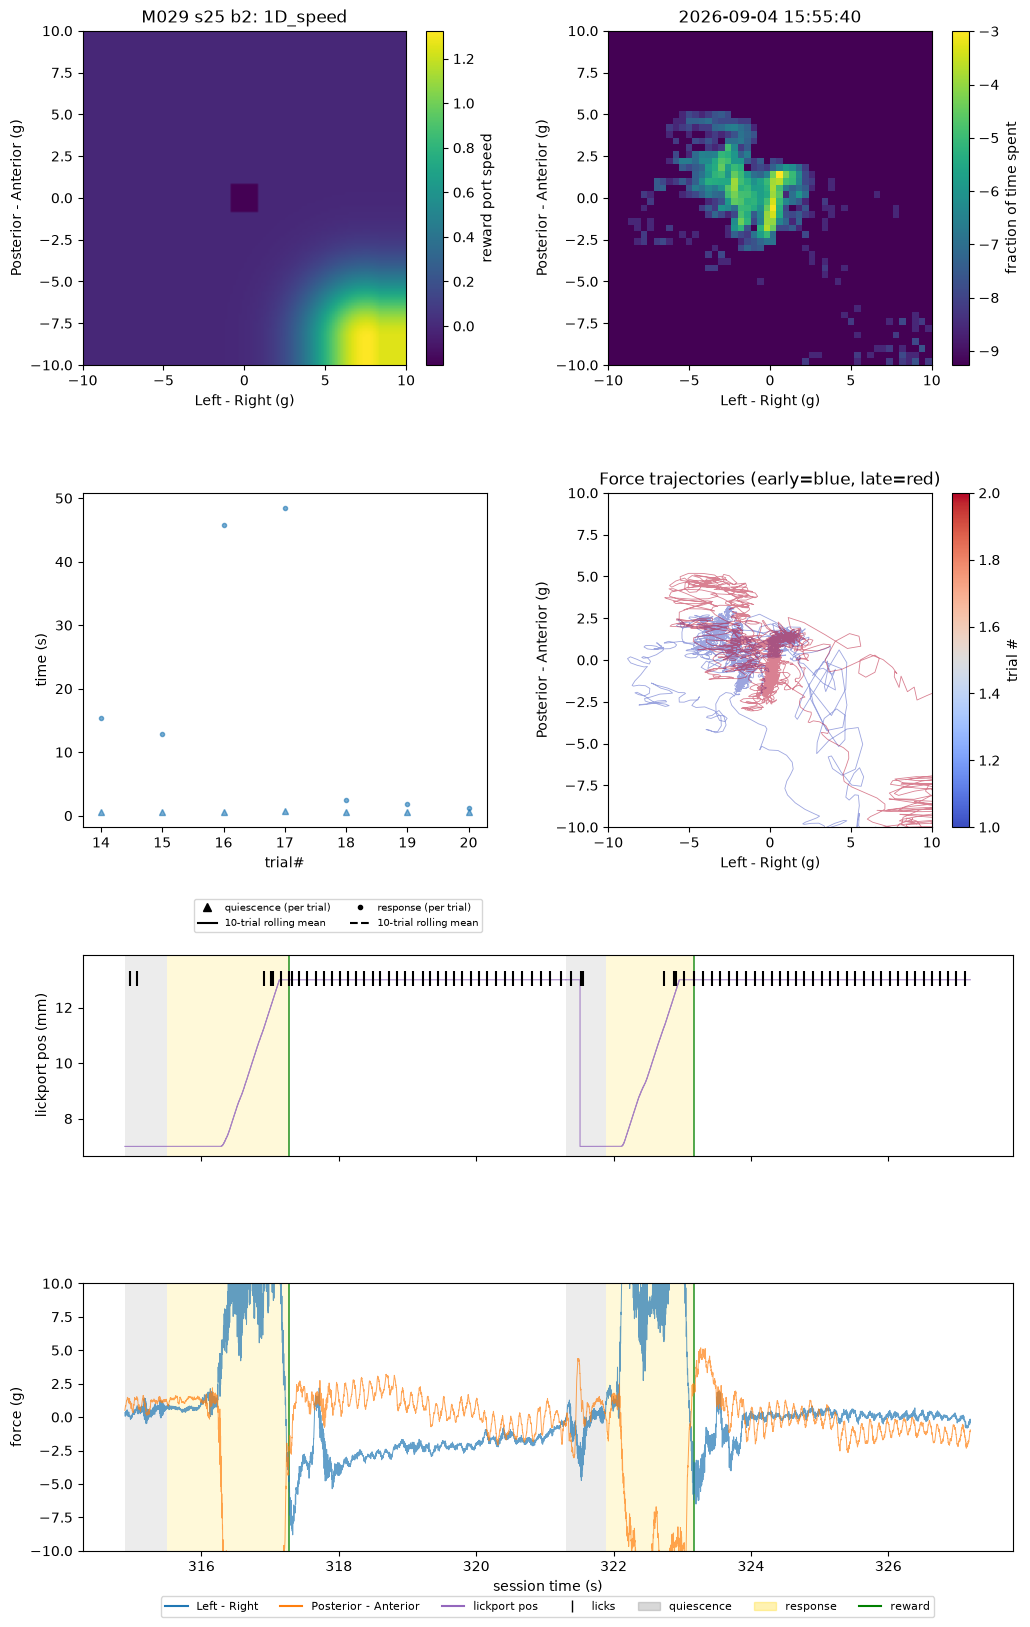

In [3]:
fig_b2_v1 = plot_block_force_figure(subject_id, session, block=2, trials=trials_by_block[2])
plt.show()

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


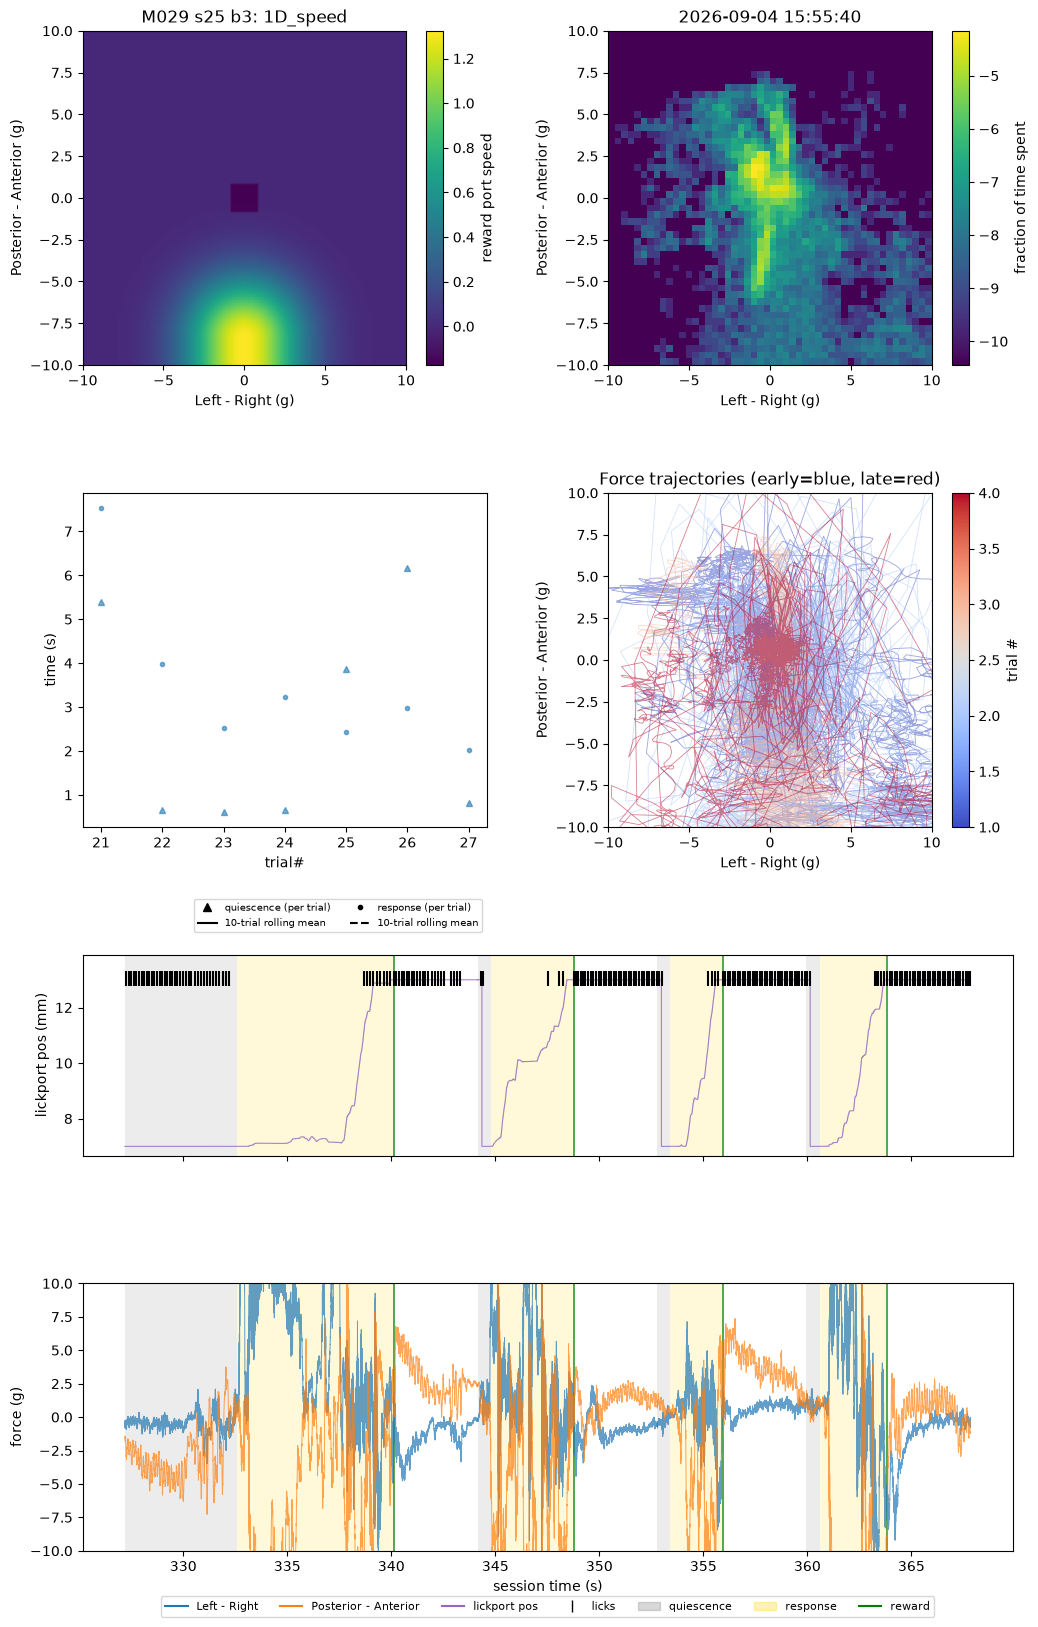

In [4]:
fig_b3_v1 = plot_block_force_figure(subject_id, session, block=3, trials=trials_by_block[3])
plt.show()

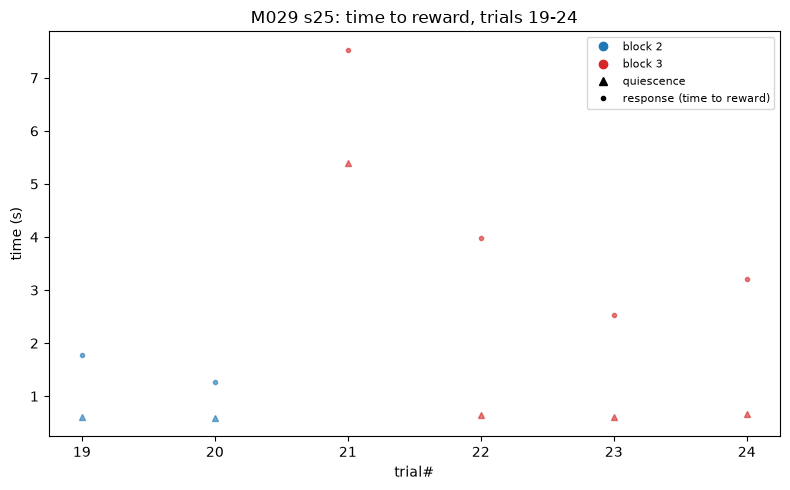

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

for block, trials in trials_by_block.items():
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    all_trials, quiescence_value, response_value = bp._fetch_quiescence_response(experiment, key)
    mask = np.isin(all_trials, trials)
    bp._plot_quiescence_response(ax, all_trials[mask], quiescence_value[mask], response_value[mask],
                                  color=block_colors[block], smoothing_window=10)

handles = [
    Line2D([0], [0], color=block_colors[2], marker='o', linestyle='None', label='block 2'),
    Line2D([0], [0], color=block_colors[3], marker='o', linestyle='None', label='block 3'),
    Line2D([0], [0], color='black', marker='^', linestyle='None', label='quiescence'),
    Line2D([0], [0], color='black', marker='.', linestyle='None', label='response (time to reward)'),
]
ax.legend(handles=handles, loc='best', fontsize=8)
ax.set_title(f'{subject_id} s{session}: time to reward, trials 19-24')
plt.tight_layout()
plt.show()

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


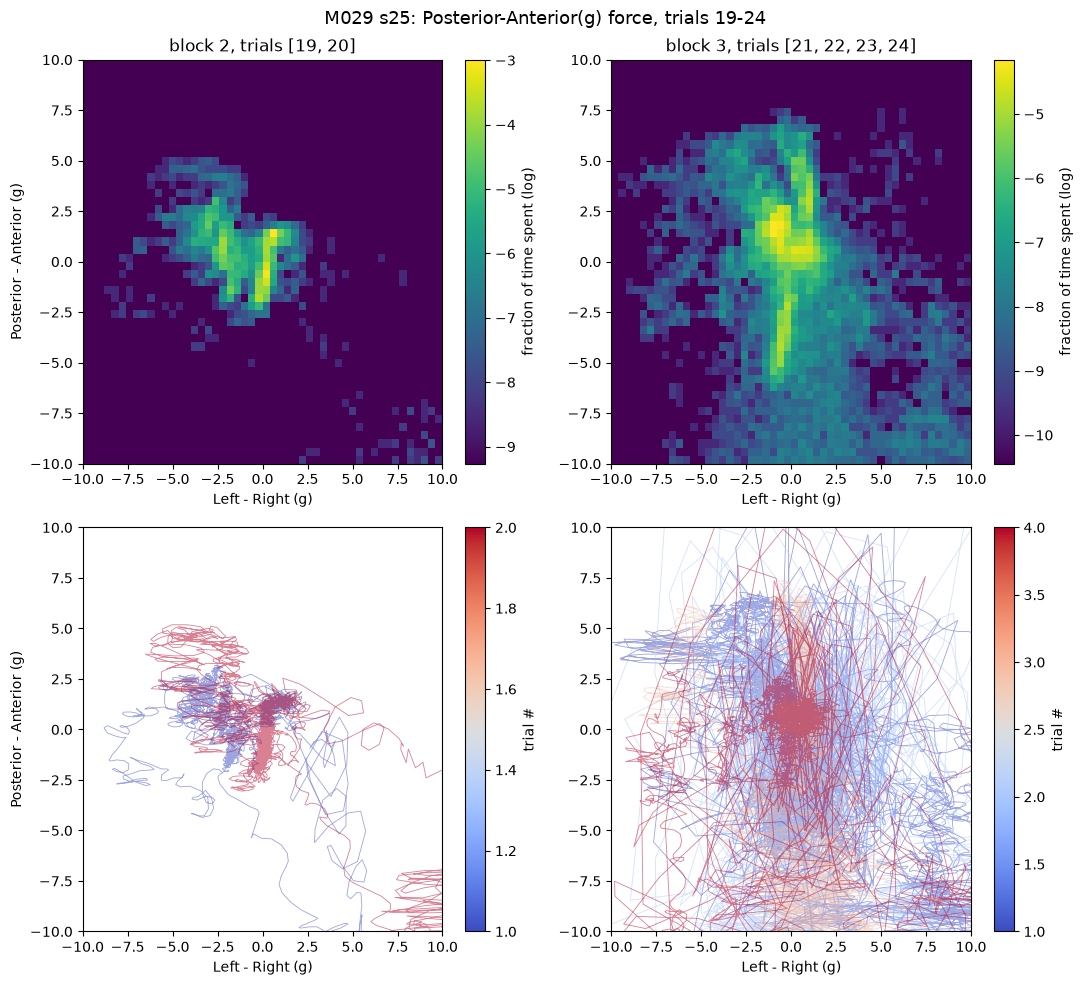

In [6]:
def lr_pa_traces_for_trials(subject_id, session, block, trials):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    _, f0_ = f0_query.fetch('trial', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')
    f0_baseline = np.median(np.concatenate(f0_))
    f1_baseline = np.median(np.concatenate(f1_))
    f0 = [f - f0_baseline for f in f0_]
    f1 = [f - f1_baseline for f in f1_]
    return bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)


uniform_range = bp.DEFAULT_UNIFORM_FORCE_RANGE
histrange = [uniform_range[:2], uniform_range[2:]]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, (block, trials) in enumerate(trials_by_block.items()):
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)

    ax_hist = axes[0, col]
    forcehist, binx, biny = bp._force_histogram(lr_traces, pa_traces, histrange)
    im = ax_hist.imshow(forcehist.T, origin='lower', extent=[binx[0], binx[-1], biny[0], biny[-1]], aspect='auto')
    ax_hist.set_xlabel('Left - Right (g)')
    if col == 0:
        ax_hist.set_ylabel('Posterior - Anterior (g)')
    ax_hist.set_title(f'block {block}, trials {trials}')
    fig.colorbar(im, ax=ax_hist, label='fraction of time spent (log)')

    ax_traj = axes[1, col]
    bp._plot_force_trajectories(ax_traj, lr_traces, pa_traces, title=None, ylabel=(col == 0))

fig.suptitle(f'{subject_id} s{session}: Posterior-Anterior(g) force, trials 19-24', fontsize=13)
plt.tight_layout()
plt.show()

## 2. Gaussian filtering, sigma = 3 ms

> "Please do the gaussian filtering to 3sigma ms"

Every force trace panel now gets gaussian-smoothed (sigma = 3 ms, converted to samples
using each block's own sample interval) before histogramming/plotting.

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


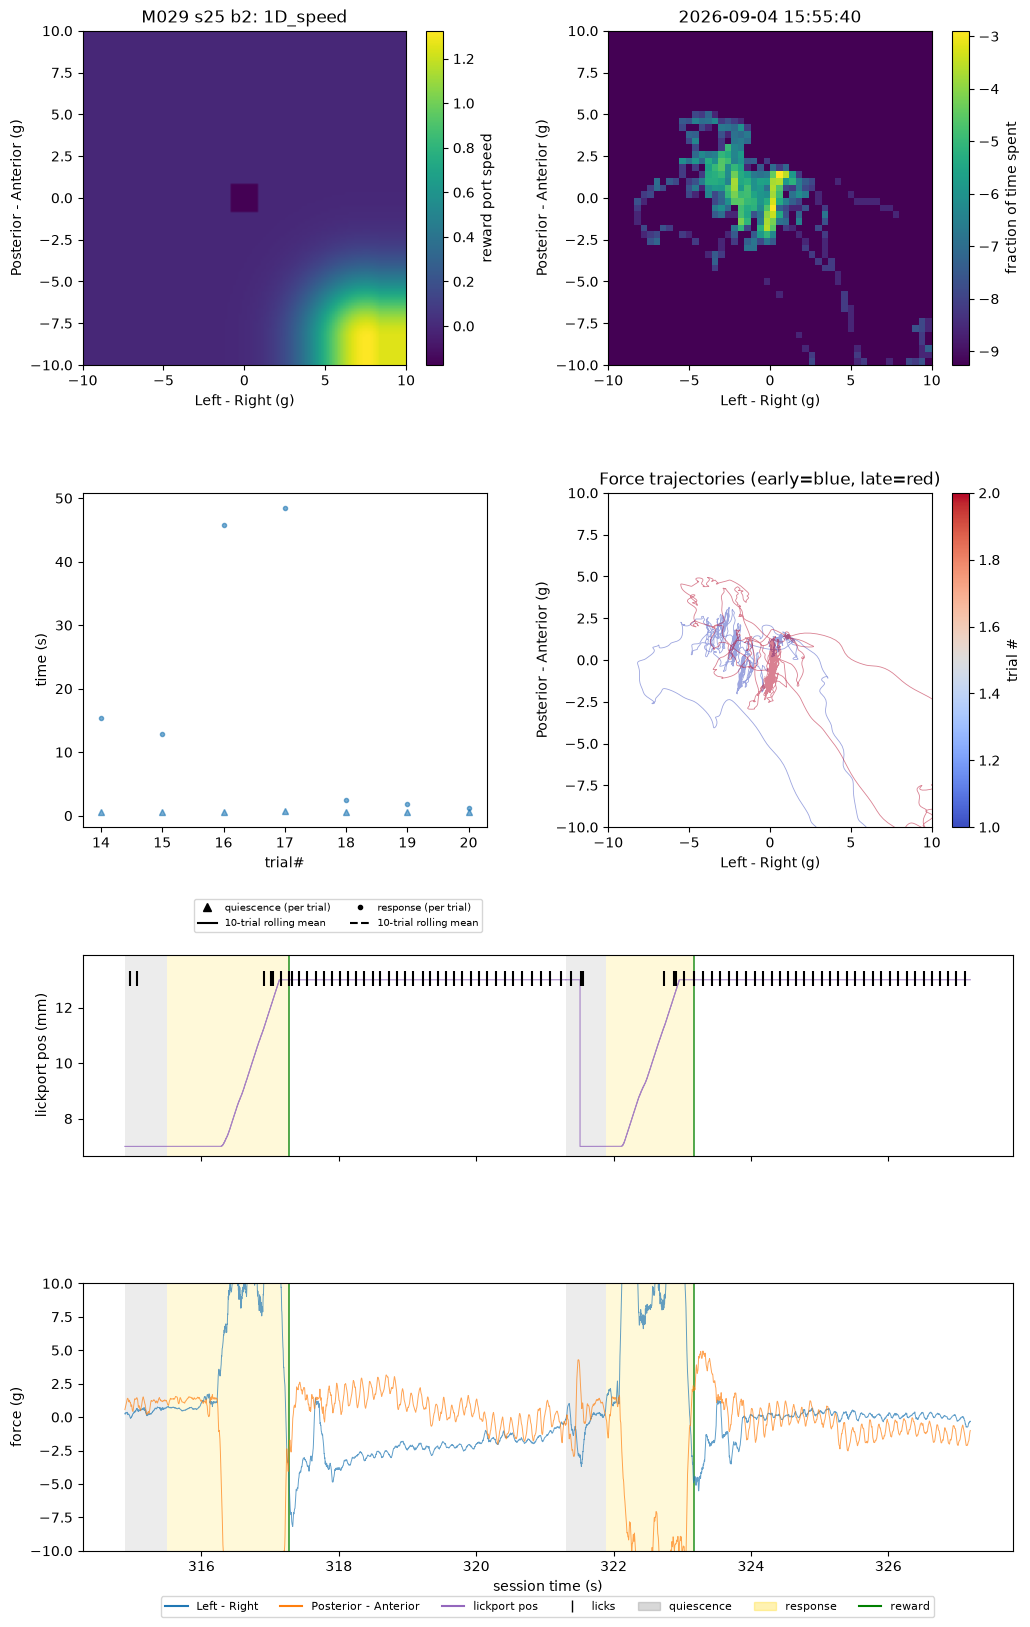

In [7]:
fig_b2_v2 = plot_block_force_figure(subject_id, session, block=2, trials=trials_by_block[2],
                                     filter_method='gaussian', filter_sigma_ms=3.0)
plt.show()

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


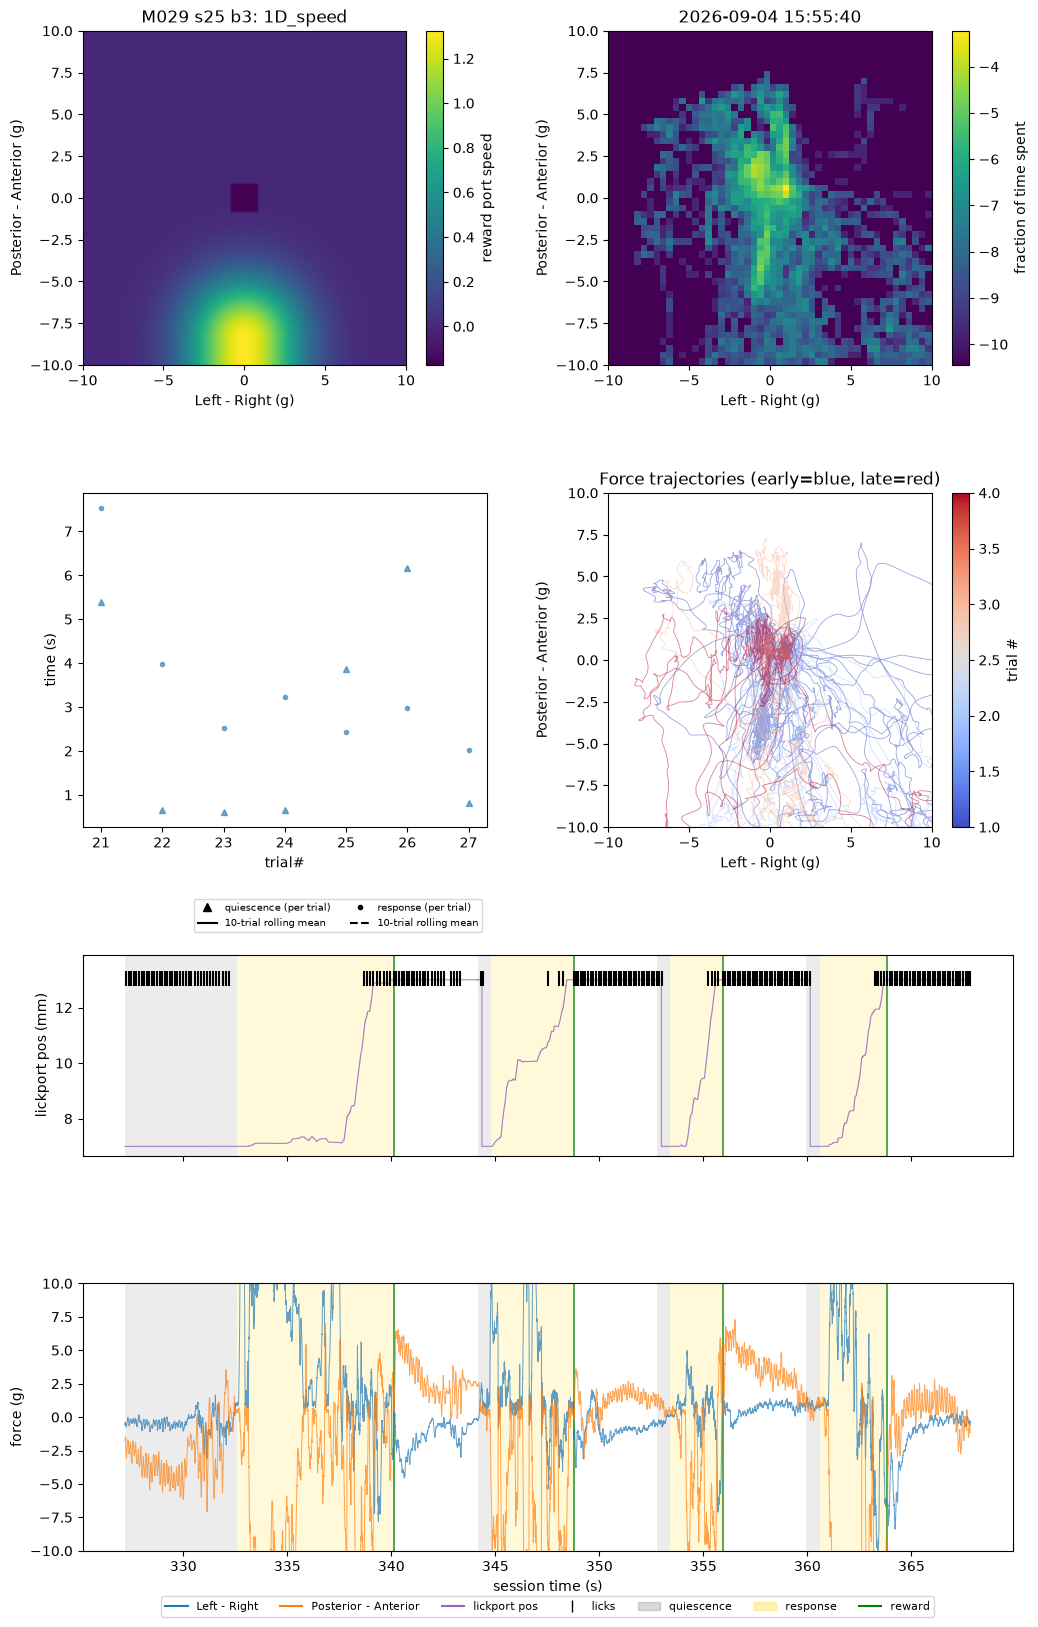

In [8]:
fig_b3_v2 = plot_block_force_figure(subject_id, session, block=3, trials=trials_by_block[3],
                                     filter_method='gaussian', filter_sigma_ms=3.0)
plt.show()

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


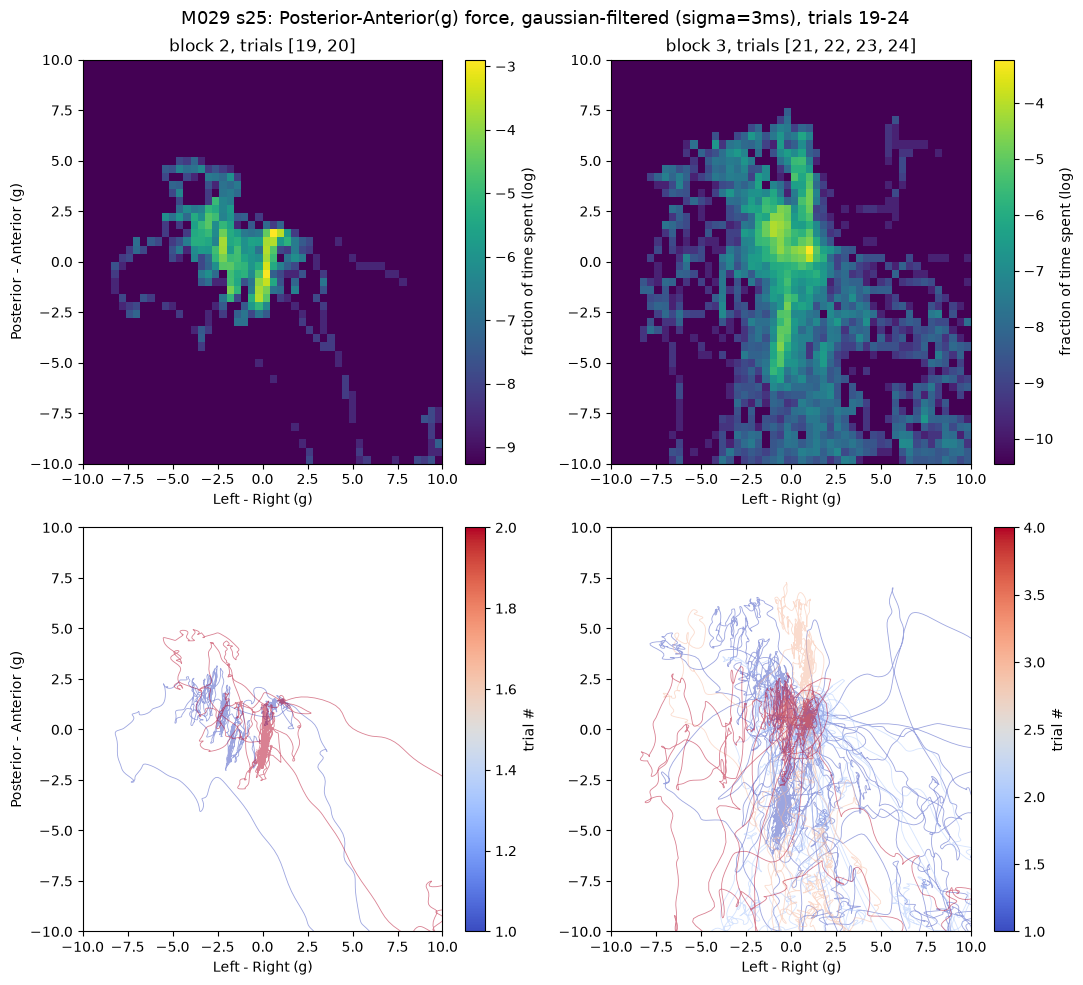

In [9]:
def lr_pa_traces_for_trials(subject_id, session, block, trials, filter_sigma_ms=3.0):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    _, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')
    f0_baseline = np.median(np.concatenate(f0_))
    f1_baseline = np.median(np.concatenate(f1_))
    f0 = [f - f0_baseline for f in f0_]
    f1 = [f - f1_baseline for f in f1_]
    lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

    sample_interval_s = bp._estimate_sample_interval(force_trace_times)
    filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
    lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)
    return lr_traces, pa_traces


uniform_range = bp.DEFAULT_UNIFORM_FORCE_RANGE
histrange = [uniform_range[:2], uniform_range[2:]]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, (block, trials) in enumerate(trials_by_block.items()):
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)

    ax_hist = axes[0, col]
    forcehist, binx, biny = bp._force_histogram(lr_traces, pa_traces, histrange)
    im = ax_hist.imshow(forcehist.T, origin='lower', extent=[binx[0], binx[-1], biny[0], biny[-1]], aspect='auto')
    ax_hist.set_xlabel('Left - Right (g)')
    if col == 0:
        ax_hist.set_ylabel('Posterior - Anterior (g)')
    ax_hist.set_title(f'block {block}, trials {trials}')
    fig.colorbar(im, ax=ax_hist, label='fraction of time spent (log)')

    ax_traj = axes[1, col]
    bp._plot_force_trajectories(ax_traj, lr_traces, pa_traces, title=None, ylabel=(col == 0))

fig.suptitle(f'{subject_id} s{session}: Posterior-Anterior(g) force, gaussian-filtered (sigma=3ms), trials 19-24', fontsize=13)
plt.tight_layout()
plt.show()

## 3. Restrict to the response epoch only

> "can you use just the epoch Response, and exclude the quiescence and reward"

All force-trace panels are now additionally masked to samples within the response
epoch (go event -> threshold crossing) only, on top of the gaussian filtering above.

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


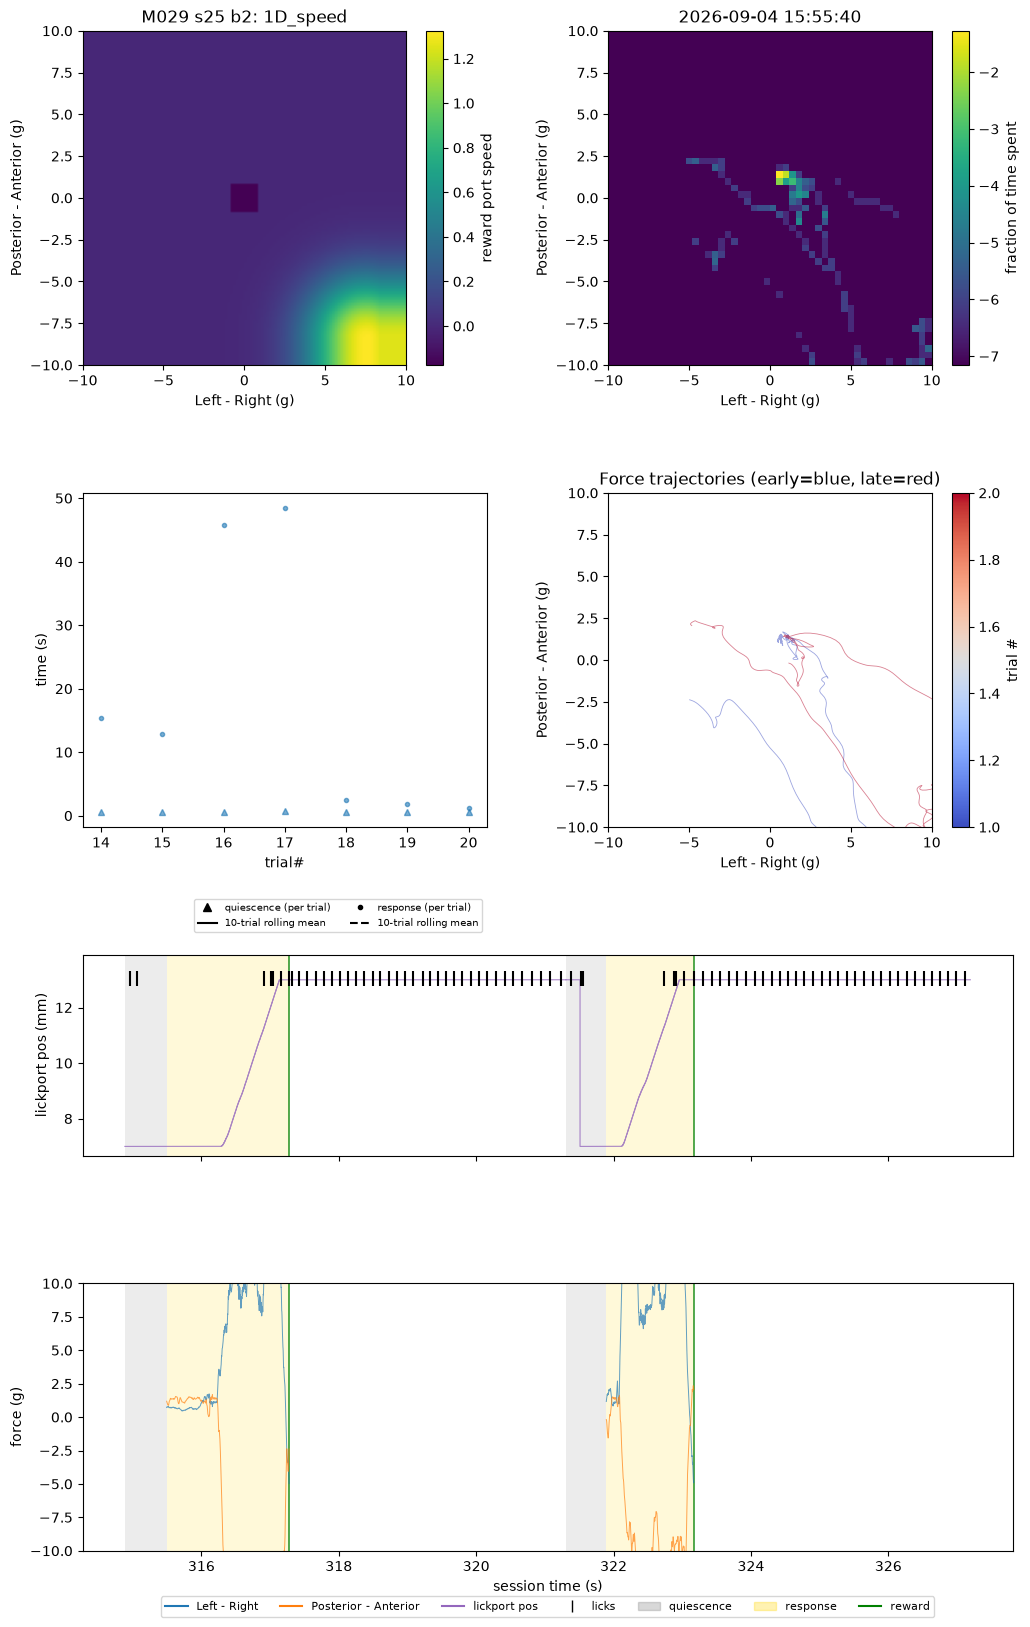

In [10]:
fig_b2_v3 = plot_block_force_figure(subject_id, session, block=2, trials=trials_by_block[2],
                                     filter_method='gaussian', filter_sigma_ms=3.0,
                                     epochs=['response'])
plt.show()

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


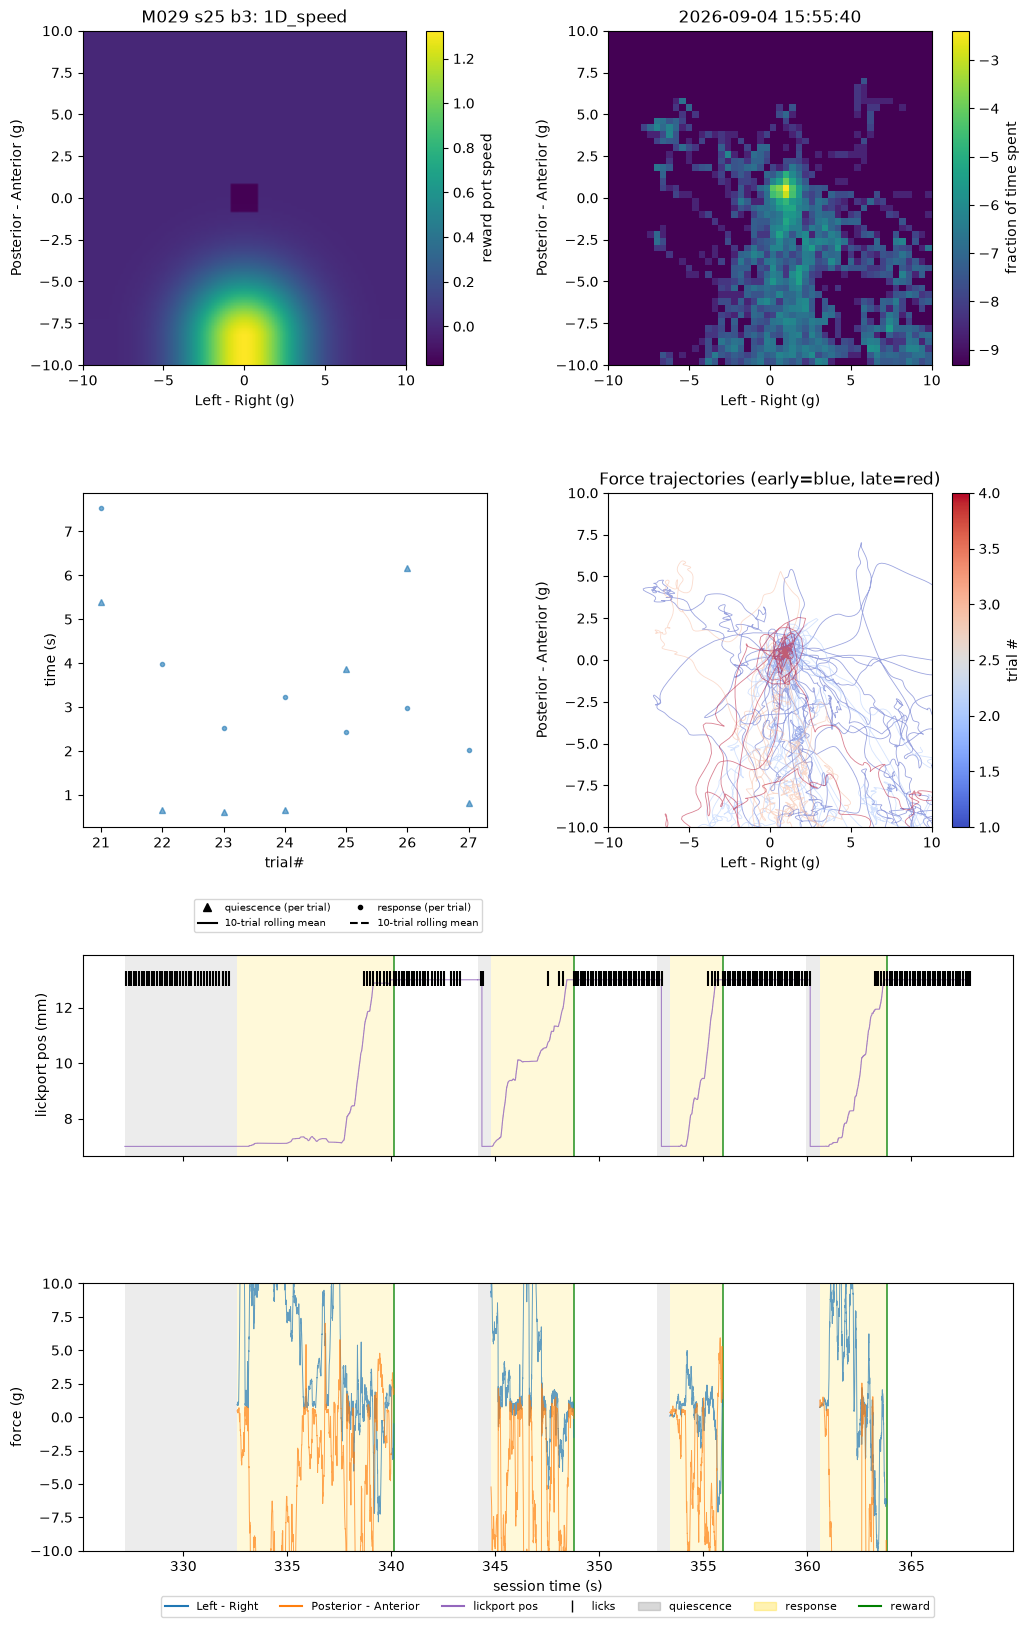

In [11]:
fig_b3_v3 = plot_block_force_figure(subject_id, session, block=3, trials=trials_by_block[3],
                                     filter_method='gaussian', filter_sigma_ms=3.0,
                                     epochs=['response'])
plt.show()

C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


C:\NDNF-pipeline\ndnf_pipeline\plot\behavior_plots.py:147: RuntimeWarning: divide by zero encountered in log
  forcehist = np.log(forcehist / forcehist.sum())


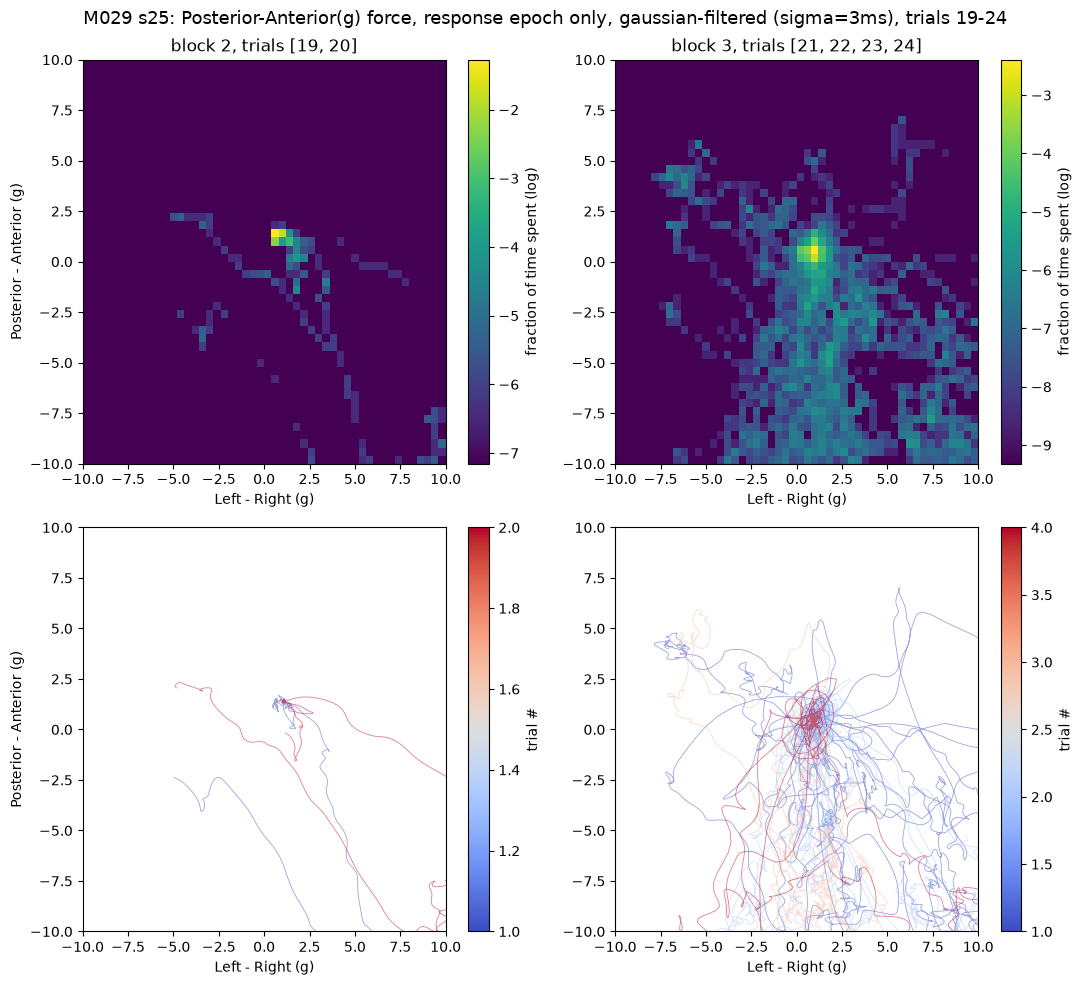

In [12]:
def lr_pa_traces_for_trials(subject_id, session, block, trials, filter_sigma_ms=3.0, epochs=('response',)):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    task_setting_id = (experiment.TaskSettings() * experiment.Block() & key).fetch1('task_setting_id')
    _, lr_idx, pa_idx, lr_sign, pa_sign = bp._get_block_force_axes(experiment, subject_id, session, task_setting_id)

    trial_restriction = [{'trial': int(t)} for t in trials]
    f0_query = (experiment.TrialForceTrace() * experiment.TrialForceTrace.TrialForceAxis()
                * experiment.BehaviorTrial() * experiment.Block() & {**key, 'force_axis_idx': 0} & trial_restriction)
    f1_query = (experiment.TrialForceTrace.TrialForceAxis() * experiment.BehaviorTrial() * experiment.Block()
                & {**key, 'force_axis_idx': 1} & trial_restriction)
    force_trials, force_trace_times, f0_ = f0_query.fetch('trial', 'force_trace_time', 'force_trace_value', order_by='trial')
    f1_ = f1_query.fetch('force_trace_value', order_by='trial')
    f0_baseline = np.median(np.concatenate(f0_))
    f1_baseline = np.median(np.concatenate(f1_))
    f0 = [f - f0_baseline for f in f0_]
    f1 = [f - f1_baseline for f in f1_]
    lr_traces, pa_traces = bp._lr_pa_traces(f0, f1, lr_idx, pa_idx, lr_sign, pa_sign)

    sample_interval_s = bp._estimate_sample_interval(force_trace_times)
    filter_sigma = bp.ms_to_samples_float(filter_sigma_ms, sample_interval_s, minimum=1e-6)
    lr_traces, pa_traces = bp._filter_traces(lr_traces, pa_traces, 'gaussian', sigma=filter_sigma)

    epoch_windows = bp._fetch_epoch_windows(experiment, key)
    lr_traces, pa_traces = bp._filter_traces_by_epochs(force_trials, force_trace_times, lr_traces, pa_traces,
                                                        epoch_windows, epochs)
    return lr_traces, pa_traces


uniform_range = bp.DEFAULT_UNIFORM_FORCE_RANGE
histrange = [uniform_range[:2], uniform_range[2:]]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, (block, trials) in enumerate(trials_by_block.items()):
    lr_traces, pa_traces = lr_pa_traces_for_trials(subject_id, session, block, trials)

    ax_hist = axes[0, col]
    forcehist, binx, biny = bp._force_histogram(lr_traces, pa_traces, histrange)
    im = ax_hist.imshow(forcehist.T, origin='lower', extent=[binx[0], binx[-1], biny[0], biny[-1]], aspect='auto')
    ax_hist.set_xlabel('Left - Right (g)')
    if col == 0:
        ax_hist.set_ylabel('Posterior - Anterior (g)')
    ax_hist.set_title(f'block {block}, trials {trials}')
    fig.colorbar(im, ax=ax_hist, label='fraction of time spent (log)')

    ax_traj = axes[1, col]
    bp._plot_force_trajectories(ax_traj, lr_traces, pa_traces, title=None, ylabel=(col == 0))

fig.suptitle(f'{subject_id} s{session}: Posterior-Anterior(g) force, response epoch only, gaussian-filtered (sigma=3ms), trials 19-24', fontsize=13)
plt.tight_layout()
plt.show()

## 4. Poster figure: Time to Reward, block 2 vs. block 3 (linear scale)

> "I need one picture that shows the Time to reward of block 2 and another one for
> block 3 [...] two pictures, side by side [...] I will be using it as a single
> picture to a poster"

Full block ranges now (block 2 = trials 14-20, block 3 = trials 21-27), only the
response duration ('time to reward') plotted, no quiescence, no rolling-mean line.

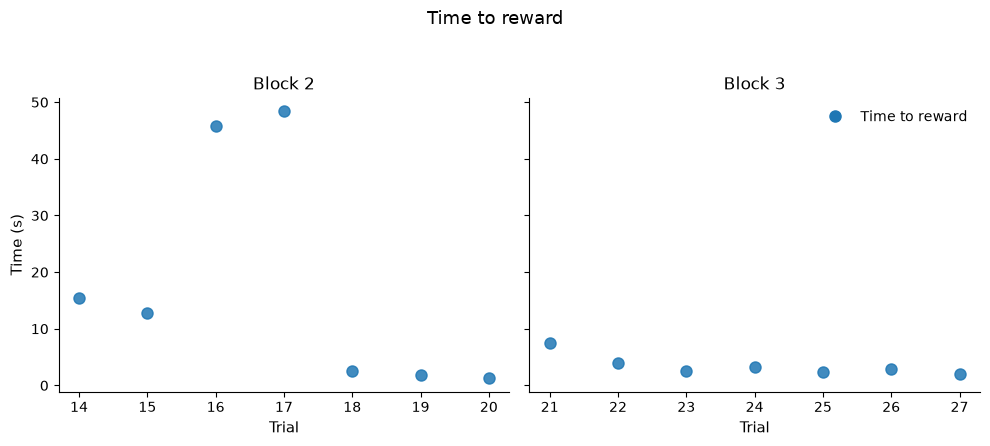

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
poster_color = 'tab:blue'

for ax, block in zip(axes, [2, 3]):
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    trials, quiescence_value, response_value = bp._fetch_quiescence_response(experiment, key)
    ax.plot(trials, response_value, 'o', color=poster_color, markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(f'Block {block}', fontsize=12)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)

axes[0].set_ylabel('Time (s)', fontsize=11)

response_handle = Line2D([0], [0], marker='o', linestyle='None', color=poster_color,
                          markersize=8, label='Time to reward')
axes[1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)

fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 5. Time-to-reward panel: quiescence markers removed (trials 19-24)

> "can you remove the quiescence triangles. change the title to Time to Reward"

Same combined block 2 / block 3 panel as section 1, but only the response ('time to
reward') markers remain.

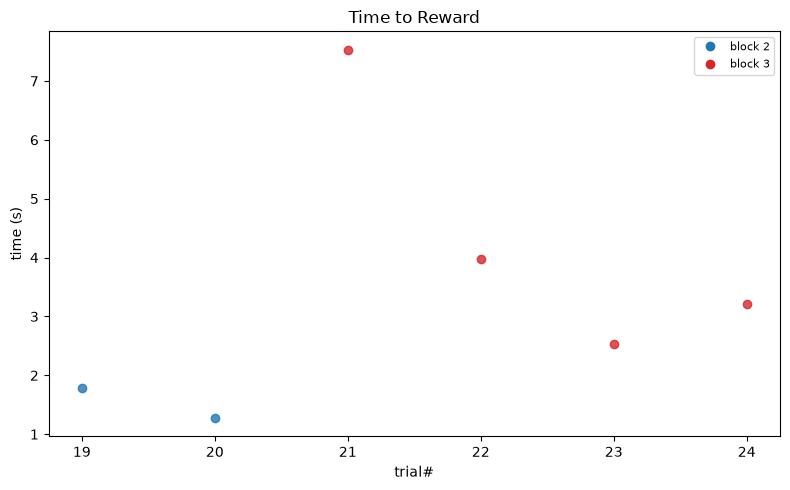

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

for block, trials in trials_by_block.items():
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    all_trials, quiescence_value, response_value = bp._fetch_quiescence_response(experiment, key)
    mask = np.isin(all_trials, trials)
    ax.plot(all_trials[mask], response_value[mask], '.', color=block_colors[block], markersize=12, alpha=0.8)

handles = [
    Line2D([0], [0], color=block_colors[2], marker='o', linestyle='None', label='block 2'),
    Line2D([0], [0], color=block_colors[3], marker='o', linestyle='None', label='block 3'),
]
ax.legend(handles=handles, loc='best', fontsize=8)
ax.set_title('Time to Reward')
ax.set_xlabel('trial#')
ax.set_ylabel('time (s)')
plt.tight_layout()
plt.show()

## 6. Poster figure: log scale + merge block 0/1 into "Block 1"

> "what if we were to use logarithmic scale. also, can you put the block 0 and 1 as
> one block, and then have the block 2 and 3 separates." Followed by "can the title
> be just Time to reward" and "the block 0 and 1 can be just block 1".

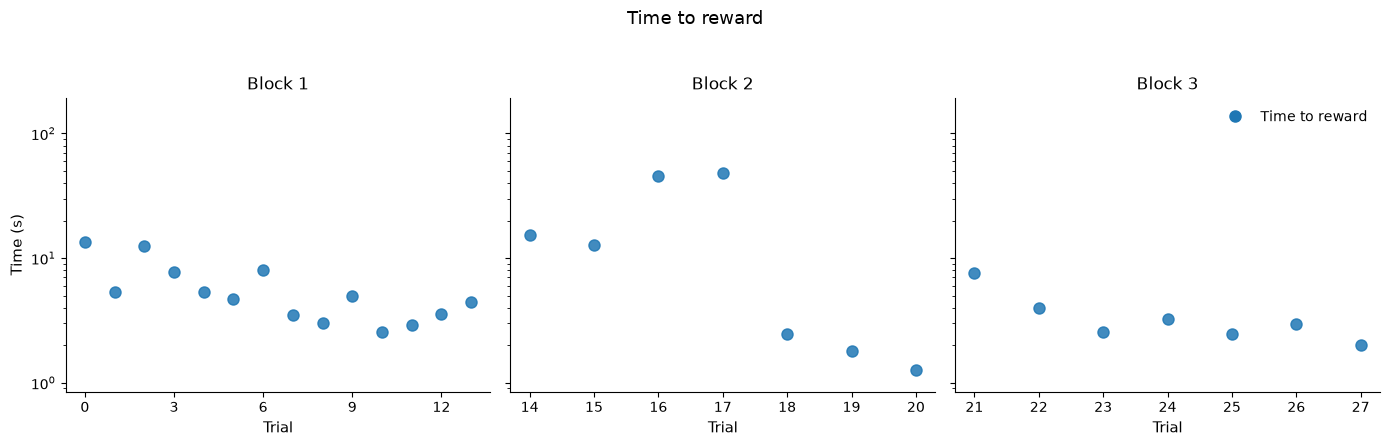

In [15]:
block_groups_3 = [('Block 1', [0, 1]), ('Block 2', [2]), ('Block 3', [3])]

def fetch_group_data(block_groups):
    group_data = []
    for label, blocks in block_groups:
        trials_parts, response_parts = [], []
        for block in blocks:
            key = {'subject_id': subject_id, 'session': session, 'block': block}
            t, _, r = bp._fetch_quiescence_response(experiment, key)
            trials_parts.append(t)
            response_parts.append(r)
        trials = np.concatenate(trials_parts)
        response_value = np.concatenate(response_parts)
        order = np.argsort(trials)
        group_data.append((label, trials[order], response_value[order]))
    return group_data

group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()
poster_color = 'tab:blue'

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, (label, trials, response_value) in zip(axes, group_data):
    ax.plot(trials, response_value, 'o', color=poster_color, markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color=poster_color,
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 7. Poster figure: single panel, color-coded (rejected)

> "can you remove the y axis that divides the blocks, and instead make the circles
> (time to reward) color coded. so each block has a color. add a legend too"

Merged all three groups onto one axes, color-coded. The user did not like this version
(reply: "i dont like it, the y axis now has different elements").

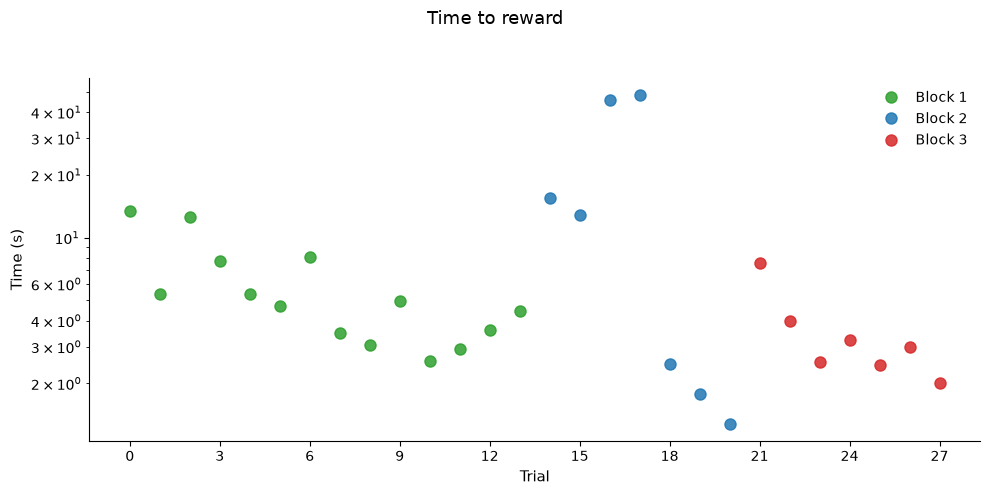

In [16]:
block_groups_colored = [('Block 1', [0, 1], 'tab:green'), ('Block 2', [2], 'tab:blue'), ('Block 3', [3], 'tab:red')]

fig, ax = plt.subplots(figsize=(10, 5))
for label, blocks, color in block_groups_colored:
    trials_parts, response_parts = [], []
    for block in blocks:
        key = {'subject_id': subject_id, 'session': session, 'block': block}
        t, _, r = bp._fetch_quiescence_response(experiment, key)
        trials_parts.append(t)
        response_parts.append(r)
    trials = np.concatenate(trials_parts)
    response_value = np.concatenate(response_parts)
    order = np.argsort(trials)
    ax.plot(trials[order], response_value[order], 'o', color=color, markersize=8, alpha=0.85, label=label)

ax.set_yscale('log')
ax.set_xlabel('Trial', fontsize=11)
ax.set_ylabel('Time (s)', fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=10)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=10))
ax.legend(loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 8. Poster figure: back to 3 panels, no dividing walls

> "i dont like it, the y axis now has different elements. We can keep it as it was
> before but just remove the y axis walls that divide the blocks"

Reverted to one subplot per block group, single color, but with the left spine/ticks
hidden on panels 2 and 3 so there is no vertical divider between them.

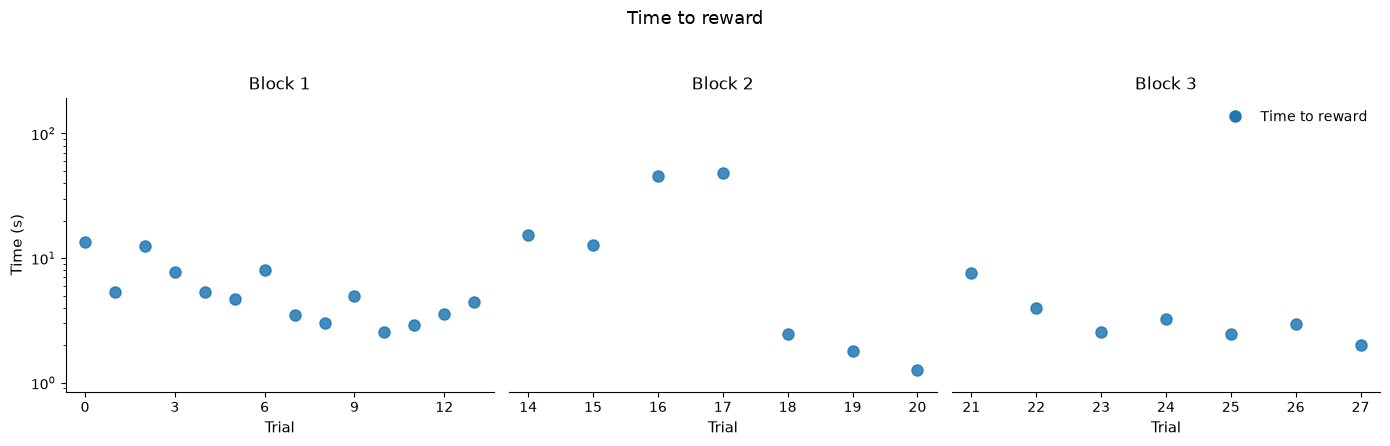

In [17]:
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()
poster_color = 'tab:blue'

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for i, (ax, (label, trials, response_value)) in enumerate(zip(axes, group_data)):
    ax.plot(trials, response_value, 'o', color=poster_color, markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)
    if i > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False, which='both')

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color=poster_color,
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 9. Poster figure: color-coded panels, no dividing walls (final)

> "just color it now"

Same layout as section 8, but each panel's markers are colored by block (green/blue/
red). This is the current main poster figure, saved at
`Notebooks/figures/M029_s25_time_to_reward_blocks_01_2_3_log.png`.

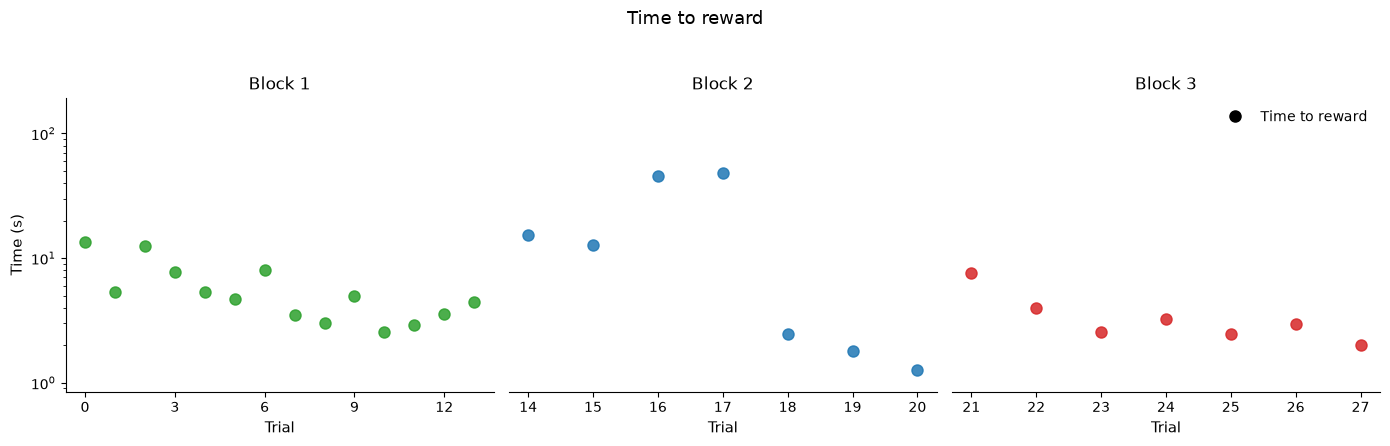

In [18]:
group_data = fetch_group_data(block_groups_3)
all_response = np.concatenate([r for _, _, r in group_data])
ymin, ymax = all_response.min(), all_response.max()
block_colors_3 = ['tab:green', 'tab:blue', 'tab:red']

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for i, (ax, (label, trials, response_value)) in enumerate(zip(axes, group_data)):
    ax.plot(trials, response_value, 'o', color=block_colors_3[i], markersize=8, alpha=0.85)
    ax.set_xlabel('Trial', fontsize=11)
    ax.set_title(label, fontsize=12)
    ax.set_yscale('log')
    ax.set_ylim(ymin / 1.5, ymax * 4)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=7))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(labelsize=10)
    if i > 0:
        ax.spines['left'].set_visible(False)
        ax.tick_params(left=False, which='both')

axes[0].set_ylabel('Time (s)', fontsize=11)
response_handle = Line2D([0], [0], marker='o', linestyle='None', color='black',
                          markersize=8, label='Time to reward')
axes[-1].legend(handles=[response_handle], loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Time to reward', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 10. Time-to-reward panel: trial range extended to 18-27 (final)

> "can it be from 18 to 27. and remove the quiescence triangles. make a fig out of it"

Same style as section 5, but block 2's range is trimmed to trials 18-20 and block 3
covers its full range, trials 21-27. Saved at
`Notebooks/figures/M029_s25_time_to_reward_trials_18_27.png`.

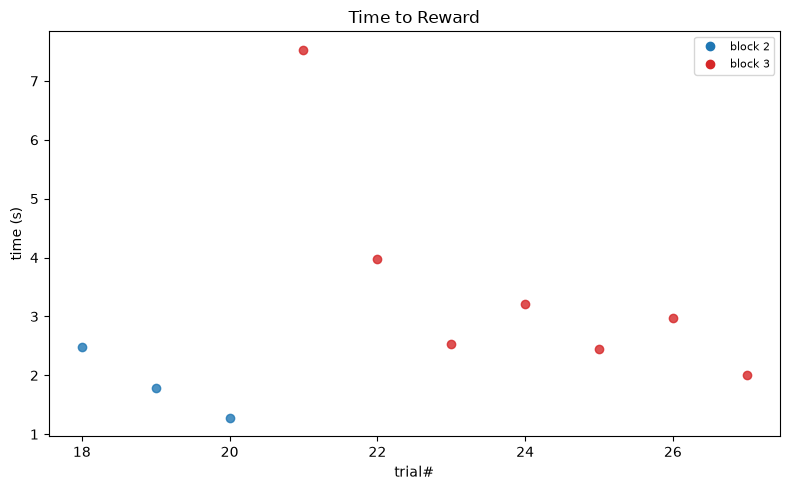

In [19]:
trials_by_block_18_27 = {2: [18, 19, 20], 3: [21, 22, 23, 24, 25, 26, 27]}

fig, ax = plt.subplots(figsize=(8, 5))

for block, trials in trials_by_block_18_27.items():
    key = {'subject_id': subject_id, 'session': session, 'block': block}
    all_trials, quiescence_value, response_value = bp._fetch_quiescence_response(experiment, key)
    mask = np.isin(all_trials, trials)
    ax.plot(all_trials[mask], response_value[mask], '.', color=block_colors[block], markersize=12, alpha=0.8)

handles = [
    Line2D([0], [0], color=block_colors[2], marker='o', linestyle='None', label='block 2'),
    Line2D([0], [0], color=block_colors[3], marker='o', linestyle='None', label='block 3'),
]
ax.legend(handles=handles, loc='best', fontsize=8)
ax.set_title('Time to Reward')
ax.set_xlabel('trial#')
ax.set_ylabel('time (s)')
plt.tight_layout()
plt.show()